# In-memory pipelines and mesh graphs: `apply_operations`, `adjacency`, `write_graph`

Two small APIs that open the rest of the library to code that never touches a file:

- **`apply_operations(mesh, operations)`** applies [settings pipeline](../../doc/pipeline.md) steps to a mesh in memory and returns `(mesh, report)` — `run_pipeline` without its Input read and Output write: the same vocabulary, the same validation of every step before any runs, the same report.
- **`adjacency(mesh, kind)`** returns the mesh's graph in compressed-sparse-row form, `(indptr, indices)`: `"node"` (nodes joined by a cell edge), `"clique"` (nodes sharing a cell: the sparsity pattern of an assembled FEM matrix) or `"cell"` (cells sharing a facet: the dual graph partitioners cut). **`write_graph`** writes one as a METIS `.graph` or Scotch `.grf` file.

See `doc/pipeline.md#in-memory-apply-operations` and `doc/adjacency.md`.

In [1]:
import os
import subprocess
import sys
import tempfile

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection, PolyCollection

import meshioplusplus as mp


def gl_available():
    # Can PyVista render off-screen here? VTK without a GL/EGL/OSMesa library aborts
    # the process instead of raising, so the probe runs in a child process.
    probe = ("import pyvista as pv; pv.OFF_SCREEN = True; "
             "pl = pv.Plotter(off_screen=True, window_size=(64, 64)); "
             "pl.add_mesh(pv.Sphere()); pl.screenshot(return_img=True)")
    try:
        return subprocess.run([sys.executable, '-c', probe], capture_output=True, timeout=120).returncode == 0
    except Exception:
        return False


try:
    import pyvista as pv

    if gl_available():
        # Head-less, static rendering (no display / live server needed).
        pv.OFF_SCREEN = True
        pv.set_jupyter_backend('static')
    else:
        pv = None
        print('No GL available: rendering with matplotlib.')
except ImportError:  # pragma: no cover - pyvista is optional here
    pv = None
    print('PyVista unavailable: rendering with matplotlib.')


def to_pyvista(mesh):
    """meshio++ Mesh -> pyvista grid via a temporary .vtu."""
    with tempfile.NamedTemporaryFile(suffix='.vtu', delete=False) as f:
        tmp = f.name
    try:
        mp.write(tmp, mesh)
        return pv.read(tmp)
    finally:
        os.unlink(tmp)


def draw(ax, mesh, scalars=None, title=None, cmap='viridis', clim=None):
    """A planar mesh on a matplotlib axis: PyVista's render embedded as an image
    when GL is available, else a PolyCollection of the cells."""
    if pv is not None:
        grid = to_pyvista(mesh)
        pl = pv.Plotter(off_screen=True, window_size=(800, 600))
        pl.add_mesh(grid, scalars=scalars, cmap=cmap, clim=clim, show_edges=True,
                    show_scalar_bar=scalars is not None)
        pl.view_xy()
        ax.imshow(pl.screenshot(return_img=True))
        pl.close()
    else:
        polys = [mesh.points[row, :2] for b in mesh.cells for row in np.asarray(b.data)]
        pc = PolyCollection(polys, edgecolor='k', linewidth=0.4,
                            facecolor='#cfe0f5' if scalars is None else None, cmap=cmap)
        if scalars is not None:
            values = np.concatenate([np.asarray(a).reshape(len(a), -1)[:, 0] for a in mesh.cell_data[scalars]])
            pc.set_array(values)
            if clim is not None:
                pc.set_clim(*clim)
            plt.colorbar(pc, ax=ax, shrink=0.8, label=scalars)
        ax.add_collection(pc)
        ax.autoscale()
        ax.set_aspect('equal')
    ax.axis('off')
    if title:
        ax.set_title(title)

No GL available: rendering with matplotlib.


## A pipeline on a mesh in memory

`Generate` builds the starting mesh from parameters, so the first call takes `None`. The second refines every quad into four, smooths the interior five times and scores the cells, exactly as the same three steps in a `settings.json` would — and returns the report a file run returns.

{'op': 'Refine'}
{'op': 'Smooth', 'NumNodesMoved': 448, 'MaxDisplacement': 0.005957134522653925, 'NumSkippedInversion': 0}
{'op': 'Quality'}
cells: 128 -> 512


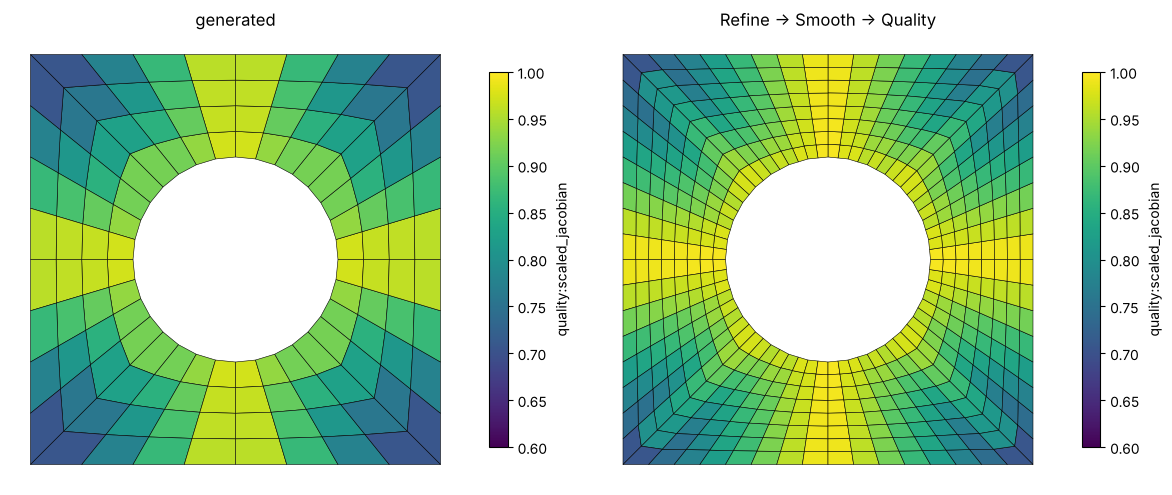

In [2]:
plate, report = mp.apply_operations(None, [
    {"Op": "Generate", "Shape": "plate_with_hole", "Nt": 8, "Nr": 4},
    {"Op": "Quality"},
])
fine, report = mp.apply_operations(plate, [
    {"Op": "Refine"},
    {"Op": "Smooth", "Iterations": 5},
    {"Op": "Quality"},
])
for step in report["steps"]:
    print(step)
print('cells:', sum(len(b.data) for b in plate.cells), '->', sum(len(b.data) for b in fine.cells))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
clim = (0.6, 1.0)
draw(axes[0], plate, 'quality:scaled_jacobian', 'generated', clim=clim)
draw(axes[1], fine, 'quality:scaled_jacobian', 'Refine -> Smooth -> Quality', clim=clim)
plt.tight_layout()
plt.show()

The input is never modified, every step is validated before the first one runs, and the steps that only make sense in a file run say so:

In [3]:
for bad in ([{"Op": "Refine"}, {"Op": "Frobnicate"}],
            [{"Op": "Clean", "Weld": True, "Tolerance": 1e-6}],
            [{"Op": "MeshCadSurface", "TargetSize": 0.1}]):
    try:
        mp.apply_operations(plate, bad)
    except ValueError as exc:
        print('ValueError:', str(exc)[:110])

ValueError: meshio++: pipeline: unknown operation 'Frobnicate' (known: Quality, Clean, Smooth, Refine, Decimate, DecimateV
ValueError: meshio++: pipeline: step 'Clean': unknown parameter 'Tolerance' (known: Weld, Atol, RemoveOrphans, DropDegener
ValueError: meshio++: pipeline: step 'MeshCadSurface': needs a CAD model, and the pipeline carries none: the mesh carries 


## The FEM sparsity pattern, before and after renumbering

`adjacency(mesh, "clique")` couples every pair of nodes that share a cell: the off-diagonal pattern of an assembled stiffness matrix, which is what a preallocation needs and what a bandwidth-reducing renumbering minimises. `scipy.sparse.csr_matrix((data, indices, indptr))` takes the arrays as they are.

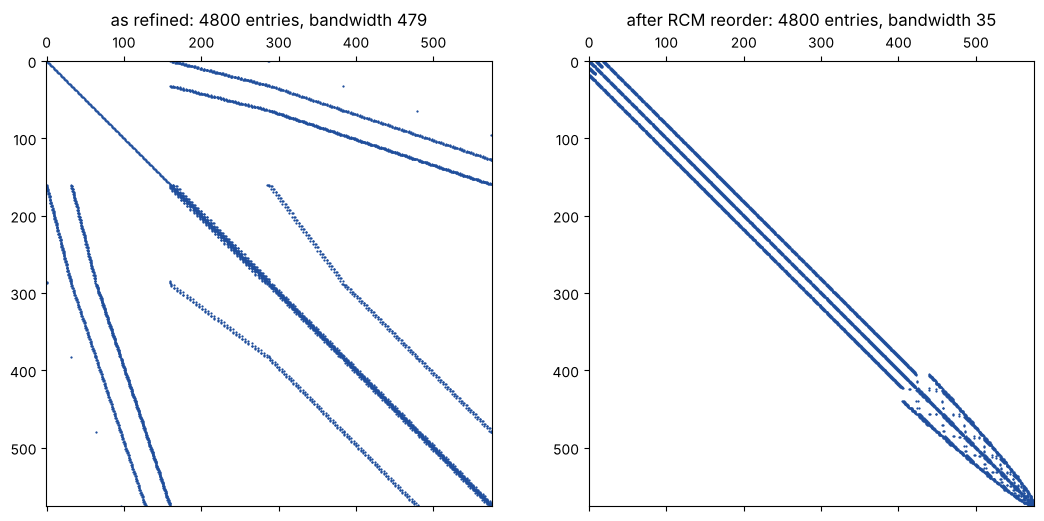

In [4]:
import scipy.sparse as sp


def pattern(mesh):
    indptr, indices = mp.adjacency(mesh, "clique")
    n = len(indptr) - 1
    return sp.csr_matrix((np.ones(len(indices)), indices, indptr), shape=(n, n)) + sp.eye(n)


renumbered = mp.reorder(fine, method="rcm")
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, m, name in ((axes[0], fine, 'as refined'), (axes[1], renumbered, 'after RCM reorder')):
    A = pattern(m)
    ax.spy(A, markersize=0.6, color='#1f4e9c')
    ax.set_title(f'{name}: {A.nnz} entries, bandwidth {mp.compute_bandwidth(m)}')
plt.tight_layout()
plt.show()

## The three graphs

The node graph follows the cell edges, so a quad's diagonals are not in it; the clique graph adds them; the cell graph joins quads that share an edge. Each row is sorted and every edge is stored in both directions, so `indptr[-1]` is twice the edge count.

node  :  160 vertices,   288 edges, degree 3..4
clique:  160 vertices,   544 edges, degree 5..8
cell  :  128 vertices,   224 edges, degree 3..4


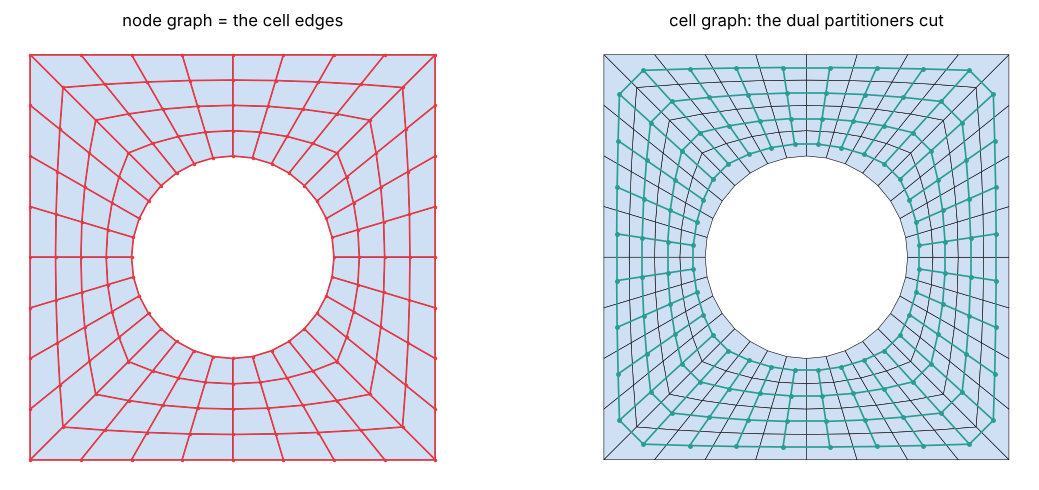

In [5]:
for kind in ("node", "clique", "cell"):
    indptr, indices = mp.adjacency(plate, kind)
    degree = np.diff(indptr)
    print(f'{kind:6s}: {len(indptr) - 1:4d} vertices, {indptr[-1] // 2:5d} edges, degree {degree.min()}..{degree.max()}')

centroids = np.array([plate.points[row, :2].mean(axis=0) for b in plate.cells for row in np.asarray(b.data)])
indptr, indices = mp.adjacency(plate, "cell")
rows = np.repeat(np.arange(len(indptr) - 1), np.diff(indptr))
upper = rows < indices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
draw(axes[0], plate, title='node graph = the cell edges')
ip, ix = mp.adjacency(plate, "node")
r = np.repeat(np.arange(len(ip) - 1), np.diff(ip))
u = r < ix
axes[0].add_collection(LineCollection(np.stack([plate.points[r[u], :2], plate.points[ix[u], :2]], axis=1),
                                      colors='#e63946', linewidths=1.2, zorder=3))
axes[0].plot(*plate.points[:, :2].T, '.', color='#e63946', markersize=3)
draw(axes[1], plate, title='cell graph: the dual partitioners cut')
axes[1].add_collection(LineCollection(np.stack([centroids[rows[upper]], centroids[indices[upper]]], axis=1),
                                      colors='#2a9d8f', linewidths=1.2, zorder=3))
axes[1].plot(*centroids.T, 'o', color='#2a9d8f', markersize=2.5)
plt.tight_layout()
plt.show()

## METIS and Scotch files

`write_graph` writes a mesh's graph (or any symmetric `(indptr, indices)` pair) for an external partitioner: METIS's `.graph` is a header `n m` and then each vertex's 1-based neighbours; Scotch's `.grf` is 0-based with each vertex's degree first. The same file comes from the CLI, `meshioplusplus graph plate.vtu plate.graph --kind cell`, and from the C, Fortran, Julia, R and WebAssembly bindings.

In [6]:
with tempfile.TemporaryDirectory() as tmp:
    for name in ("plate.graph", "plate.grf"):
        path = os.path.join(tmp, name)
        print(name, mp.write_graph(path, plate, "cell"))
        with open(path) as fh:
            print(''.join(fh.readlines()[:5]))

plate.graph {'format': 'metis', 'num_vertices': 128, 'num_edges': 224, 'max_degree': 4}
128 224
2 32 33
1 3 34
2 4 35
3 5 36

plate.grf {'format': 'scotch', 'num_vertices': 128, 'num_edges': 224, 'max_degree': 4}
0
128 448
0 000
3 1 31 32
3 0 2 33

